# ¿Como ejecutar?

- crear entorno virtual de pyhton

    *python -m venv 'nombre del env'*

    *source 'nombre del env'/bin/activate*

- poner en la misma carpeta el archivo 'sopa_letras.png'

- ejecutar todas las celdas

- paso 4: disfrutar

In [89]:
!pip install opencv-python
!pip install matplotlib
!pip install pandas
!pip install scipy

In [90]:
import cv2
import matplotlib.pyplot as plt
import pandas as pd
import math
import scipy
import numpy as np


Se lee imagen en escala de grises para facilitar el analisis (y porque no necesitamos los 3 canales)

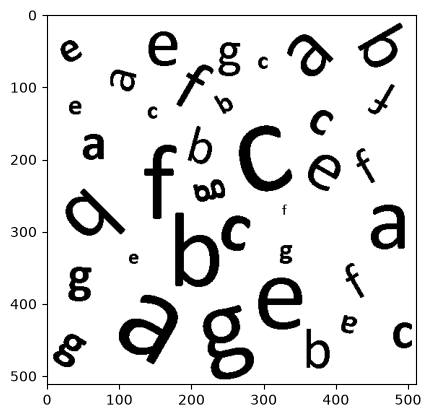

In [91]:
img = cv2.imread('sopa_letras.png', cv2.IMREAD_GRAYSCALE)


plt.figure()
plt.imshow(img, cmap='gray')
plt.show()

In [92]:
dimensions = img.shape 
print('Image Dimension: ',dimensions)

Image Dimension:  (512, 512)


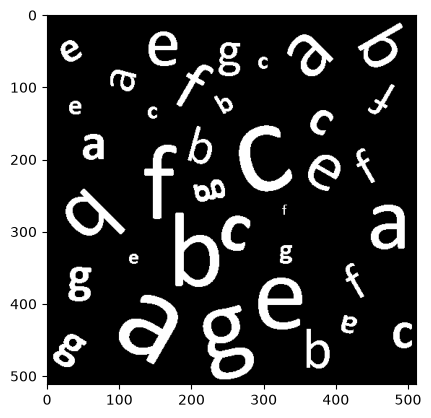

In [93]:
_, imagenInvertida = cv2.threshold(img, 2, 255, cv2.THRESH_BINARY_INV)

plt.figure()
plt.imshow(imagenInvertida, cmap='gray')
plt.show()


Letras encontradas: 36


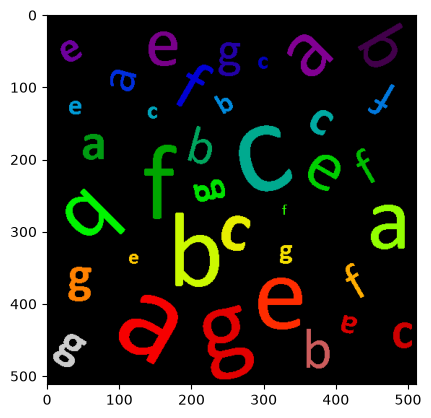

In [109]:

num, labels, stats, centroids = cv2.connectedComponentsWithStats(imagenInvertida, connectivity=8)

letras = []
letras_identificadas = []

areaImagen = 25

for i in range(1, num):        # 0 es el fondo, se salta
    area = stats[i, cv2.CC_STAT_AREA]
    if area < areaImagen:
        continue               # descarta ruido

    x = stats[i, cv2.CC_STAT_LEFT]
    y = stats[i, cv2.CC_STAT_TOP]
    w = stats[i, cv2.CC_STAT_WIDTH]
    h = stats[i, cv2.CC_STAT_HEIGHT]
    
    componente = (labels == i).astype(np.uint8) * 255

    # Recorte de la letra
    recorte = componente[y:y+h, x:x+w]

    letras.append(recorte)
    letras_identificadas.append(i)

print(f"Letras encontradas: {len(letras_identificadas)}")

plt.imshow(labels, cmap='nipy_spectral')

plt.show()

### Vemos que las imagenes ya estan binarizadas gracias a pasar la imagen a escala de grises
**fondo = 255**


**objeto = 0**

### Se procede a definir las funciones necesarias para calcular los momentos de Hu

In [95]:
def mrs(r, s, I, J):
    i=I**r
    j=J**s
    return np.sum(i*j)

In [96]:
def  m_central(r, s, I, J):
    m00 = mrs(0,0,I,J)
    m10 = mrs(1,0,I,J)
    m01 = mrs(0,1,I,J)

    ci = m10/m00
    cj = m01/m00
    i = (I-ci)**r
    j = (J-cj)**s

    return sum(i*j)

In [97]:
def eta(r, s, I, J):

    t = (r+s)/2 + 1
    a =  m_central(r,s,I,J)
    b =  m_central(0,0,I,J)

    return a/(b**t)

In [98]:
def hu(I, J):
    H= np.zeros(4)
    eta11 = eta(1,1,I,J)
    eta12 = eta(1,2,I,J)
    eta20 = eta(2,0,I,J)
    eta21 = eta(2,1,I,J)
    eta02 = eta(0,2,I,J)
    eta03 = eta(0,3,I,J)
    eta30 = eta(3,0,I,J)

    H[0] = eta20+eta02
    H[1] = (eta20-eta02)**2 + 4*eta11**2
    H[2] = (eta30-3*eta12)**2+(3*eta21-eta03)**2
    H[3] = (eta30+eta12)**2+(eta21+eta03)**2
    return H

### Por ultimo se calcula y guarda los momentos hu por cada letra

Momentos de Hu normalizados con logaritmo para facilitar su analisis

In [99]:
listaDeMomentos = []
for i in range(0,36):
    cij = np.argwhere(letras[i]==0)
    huMoments = hu(cij[:,0], cij[:,1])
    for i in range(0,4):
        huMoments[i] = -1* math.copysign(1.0, huMoments[i]) * math.log10(np.abs(huMoments[i]))
    listaDeMomentos.append(huMoments)
print(listaDeMomentos)


[array([-0.02408623,  1.59431289,  3.31136807,  1.61509097]), array([0.58078951, 2.98854426, 3.70938106, 4.19490545]), array([0.47161513, 2.32131677, 3.0148553 , 3.31862356]), array([0.53477832, 2.49484727, 4.05314208, 4.34959992]), array([0.39254052, 2.94510564, 5.67489908, 2.73285476]), array([0.43447085, 1.78274687, 2.81299867, 3.61895556]), array([0.39015244, 2.33092661, 1.92519063, 2.21183262]), array([0.62878752, 2.57311773, 3.96104824, 3.81059519]), array([0.50055974, 2.24216896, 3.90005057, 3.29312544]), array([0.63008302, 2.61535861, 4.11168021, 3.87494486]), array([0.46226958, 2.40834265, 3.08782956, 3.46317101]), array([0.23437892, 2.30316634, 2.34979968, 2.4980925 ]), array([0.39015244, 2.33092661, 1.92519063, 2.21183262]), array([0.53041909, 2.50351463, 3.38524743, 2.75740411]), array([0.62021069, 2.69645793, 3.65972154, 3.438631  ]), array([0.52760926, 1.83977718, 3.06685213, 3.56198946]), array([0.31160698, 1.69394729, 1.78772813, 2.6035984 ]), array([0.42939835, 1.29142

### Calculamos el perimetro, para esto sacamos el contorno con RETR_EXTERNAL por que saca los puntos externos obviando los contronos internos de las letras Y calculamos finalmente el perimetro como tal con arcLength ya que toma las distancias eucilidianas de los puntos del contorno y las suma

In [100]:
listaDeperimetros = []
for i in range(0,36):
    contours, _ = cv2.findContours(letras[i], cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_NONE)

    for c in contours:
        perimetro = cv2.arcLength(c, closed=True)
        listaDeperimetros.append(perimetro)
print(listaDeperimetros)

[2044.0, 226.35028612613678, 206.71067690849304, 251.7056245803833, 129.1959581375122, 188.71067690849304, 67.11269783973694, 215.1787132024765, 150.32590091228485, 153.5807341337204, 88.91168737411499, 81.4558436870575, 67.11269783973694, 140.36753106117249, 381.0193328857422, 163.29646337032318, 153.49747383594513, 310.6690467596054, 153.09545290470123, 214.30865597724915, 161.63960921764374, 263.9898953437805, 38.485281229019165, 267.6812393665314, 328.02438521385193, 196.85281229019165, 98.5269113779068, 59.79898953437805, 153.09545290470123, 184.71067690849304, 316.8944424390793, 385.74725472927094, 391.36247873306274, 105.01219260692596, 143.39696860313416, 172.42640614509583]


### Ahora la redondez con la formula R = (4 * pi * A)/p^2

puntos cuenta las cordenadas donde hay 0, luego si contamos esos pares ordenados obetemos el area de la figura

In [101]:
listaDeRedondeces = []
for i in range(0,36):
    puntos = np.argwhere(letras[i]==0)
    
    R = (4 * len(puntos) * math.pi) / (listaDeperimetros[i]**2) 
    listaDeRedondeces.append(R)
print(listaDeRedondeces)

[0.10370873531406519, 0.6455556007122775, 0.27879975196692114, 0.47563433965790325, 0.32598671850884964, 0.23571834411726464, 0.25109784126875195, 0.5997959453950265, 0.32975920455320973, 0.6238688197375627, 0.5833889830405291, 0.2026511857076465, 0.25109784126875195, 0.4049955646829163, 0.38181492184557736, 0.5508975198373869, 0.18347032975829788, 0.3873475954898256, 0.46430479873862845, 0.35514453098377985, 0.3001227174329632, 0.6558107893930969, 0.5430008495046988, 0.2309722314628311, 0.41926832378904716, 0.3236362483293762, 0.18511267811642884, 0.20733574649906597, 0.46430479873862845, 0.22062396566637466, 0.28318169205718285, 0.41034682278096085, 0.3513161825130162, 0.292862344282047, 0.27072829568929857, 0.4218255219612373]


### Para calcular el angulo de la elipse se usa la implementacion del profe del algoritmo de Fitzgibbon (porque el modelo de skiimage me da error y parecer ser un problemas de las librerias)

Al usar np.arctan2 los angulos estan en radianes en el rango [-pi, pi]. Angulo positivo -> sentido antihorario desde 0, Angulo negativo -> sentido horario desde el 0

In [102]:
listaDeAngulos = []

def fitzgibbon(x, y):
    # algoritmo de Fitzgibbon (1996) para la estimación de una elipse
    # a partir de las coordenadas de la frontera de una región

    n = x.shape[0]                                  #puntos de la frontera
    D = [x**2, x*y, y**2, x, y, np.ones((n,1))]     # matriz X
    D = np.hstack(D)
    S = np.matmul(D.T,D)                            # matriz dispersión
    C = np.zeros((6,6))
    C[0,2]=2; C[1,1]=-1; C[2,0]=2;                  # matriz restricción

    # Problema: S·a = lambda·C·a
    # --> Solución a traves de Eigenvalues
    E,V = scipy.linalg.eig(S, C)
    idx = np.where((E > 0) & np.isfinite(E))[0]
    params = V[:,idx]                                    # seleccionamos el valor propio
    return params

def parametros(x, y):
    # Funcion que busca los parametros parametricos
    # de la elipse segun las coordendas de los bordes.

    # parametros de fitzgibbon
    a,b,c,d,e,f = fitzgibbon(x, y)

    #estimados de angulos y factores de Fitzgibbon
    alpha = np.arctan2(b,a-c)/2

    ct = np.cos(alpha)
    st = np.sin(alpha)
    ap = a*ct*ct + b*ct*st + c*st*st
    cp = a*st*st - b*ct*st + c*ct*ct

    #% get translations
    T = np.array([[a,  b/2],
                  [b/2, c]])
    T = T.reshape(2,2)
    t = -1* np.matmul(np.linalg.inv(2*T),np.array([d, e]).reshape(2,1))
    cx = t[0]
    cy = t[1]

    #% factor de escala
    val = np.matmul(t.T,np.matmul(T,t))
    scale = 1 / (val- f)

    #% parametros
    r1 = 1/np.sqrt(scale*ap)
    r2 = 1/np.sqrt(scale*cp)
    v = alpha.ravel()
    return v


#puntos de la elipse



for i in range(0,36):
#buscamos las coordenadas de los contornos
    contours, _ = cv2.findContours(letras[i],cv2.RETR_EXTERNAL,cv2.CHAIN_APPROX_NONE)

    #generamos una matriz (fila/columna) con los contornos
    contornos = np.vstack(contours[0])

    #extraemos las coordenadas x,y
    x , y = zip(*contornos)
    x = np.array(x).reshape(-1,1)
    y = np.array(y).reshape(-1,1)

    #extraemos los parámetros de la elipse
    # xc, yc, a, b, theta
    v = parametros(x,  y)

    listaDeAngulos.extend(v)


print(listaDeAngulos)




[np.float64(-0.8090672776310858), np.float64(0.8402660403252552), np.float64(-0.10021025530160559), np.float64(0.7453128849648248), np.float64(0.9546039790338039), np.float64(-1.4872921280098677), np.float64(-1.570796326794887), np.float64(-0.8903375865004751), np.float64(0.20394935096114272), np.float64(0.6827582578945797), np.float64(0.7843107793365874), np.float64(-0.09092682811471009), np.float64(-1.570796326794887), np.float64(0.5569751833261144), np.float64(1.3330435824205011), np.float64(-1.5144129106532493), np.float64(1.530972562458027), np.float64(-1.41359486261498), np.float64(1.2005178786399802), np.float64(-1.1441877760106498), np.float64(-0.17154422963938362), np.float64(-1.001857606420603), np.float64(0.16492202750379326), np.float64(1.5101078306027924), np.float64(1.3608347823776503), np.float64(0.28788943120553456), np.float64(-1.4675476371821534), np.float64(-0.04747893642530235), np.float64(1.2005178786399802), np.float64(-1.4673454245721091), np.float64(-0.100310125

### Procedemos a desplegar el dataframe con los datos

In [103]:
columnas = ['Perimetro','Redondez']
filas = [
    'Letra1',  'Letra2',  'Letra3',  'Letra4',  'Letra5',  'Letra6',
    'Letra7',  'Letra8',  'Letra9',  'Letra10', 'Letra11', 'Letra12',
    'Letra13', 'Letra14', 'Letra15', 'Letra16', 'Letra17', 'Letra18',
    'Letra19', 'Letra20', 'Letra21', 'Letra22', 'Letra23', 'Letra24',
    'Letra25', 'Letra26', 'Letra27', 'Letra28', 'Letra29', 'Letra30',
    'Letra31', 'Letra32', 'Letra33', 'Letra34', 'Letra35', 'Letra36',
]

momentos = pd.DataFrame(listaDeMomentos, columns=['Hu1', 'Hu2','Hu3','Hu4'], index=filas)

perimetros = pd.DataFrame(listaDeperimetros, index=filas, columns= ['Perimetro'])

redondeces =pd.DataFrame(listaDeRedondeces, index=filas, columns=['Redondez'])

angulos = pd.DataFrame(listaDeAngulos, index=filas, columns=['Angulo'])




final = pd.concat([momentos, perimetros, redondeces, angulos], axis = 1)


final.head(36)



,Hu1,Hu2,Hu3,Hu4,Perimetro,Redondez,Angulo
Letra1,-0.024086,1.594313,3.311368,1.615091,2044.000000,0.103709,-0.809067
Letra2,0.580790,2.988544,3.709381,4.194905,226.350286,0.645556,0.840266
Letra3,0.471615,2.321317,3.014855,3.318624,206.710677,0.278800,-0.100210
Letra4,0.534778,2.494847,4.053142,4.349600,251.705625,0.475634,0.745313
Letra5,0.392541,2.945106,5.674899,2.732855,129.195958,0.325987,0.954604
Letra6,0.434471,1.782747,2.812999,3.618956,188.710677,0.235718,-1.487292
Letra7,0.390152,2.330927,1.925191,2.211833,67.112698,0.251098,-1.570796
Letra8,0.628788,2.573118,3.961048,3.810595,215.178713,0.599796,-0.890338
Letra9,0.500560,2.242169,3.900051,3.293125,150.325901,0.329759,0.203949
Letra10,0.630083,2.615359,4.111680,3.874945,153.580734,0.623869,0.682758


### Ahora se procede a calcular y mostrar los centros de masa

como los recortes los hice manuales hay que agregarles el offset de donde se hizo el recorte, para pasar la coordenada local del centro de masa a la coordenada global adecuada

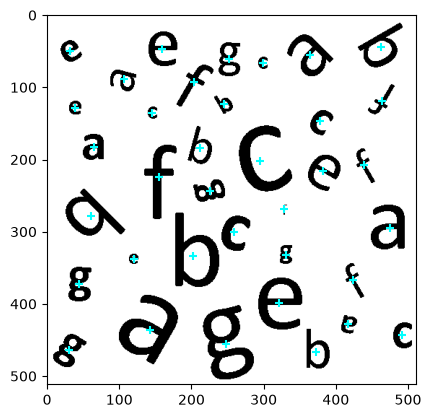

In [110]:
listaDeCentros = []
puntoX = []
puntoY = []
for i in range(1,num):
    cx, cy = centroids[i]
    puntoX.append(cx)
    puntoY.append(cy)



plt.imshow(img, cmap='gray')
plt.scatter(puntoX,puntoY, c='cyan',marker='+')
plt.show()

besitos en la cola MJDL